# SeDriCa Perception · Q2(c), (d), (e)

## Part (c)
Image-only rule: no scores, no V2X. Coordinates are `(row, col)`, origin top-left. `crossing_reference.csv` is never used by a rule.

| | part (b) baseline | part (c) revision |
|---|---|---|
| Person | `person_score` vs `thv3` | leftmost dark-blue pixel vs right road boundary |
| Light | `v2x_light` + `red_score` | red / green lamp pixels |
| V2X message | used (misleads when old) | not used |
| Final | more cautious of light and person (STOP > SLOW > GO) | same |

**GO** keep going · **SLOW** reduce speed so the car can easily stop · **STOP** complete halt (speed = 0).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import pandas as pd       # extra: just to read the CSV and show tables

## 1 · Frame where the old message misleads
`age = time_s − v2x_sample_time_s` is added in `crossing_evidence_with_age.csv`. Line 38 is `late_red` frame 12.

In [2]:
DATA = "SeDriCa_perception_starter_data/city/"
ev = pd.read_csv(DATA + "crossing_evidence_with_age.csv")
EPISODES = ["clear_green", "late_red", "person_crossing"]

def load(ep, f):
    """Frame as an RGB int array (320 x 480 x 3)."""
    return cv.cvtColor(cv.imread(f"{DATA}crossing/{ep}/{f:03d}.png"), cv.COLOR_BGR2RGB).astype(int)

print("old messages (age > 0):", (ev.age > 0).sum(), "of", len(ev), "rows")
row = ev.iloc[36]                         # line 38 of the file (header = line 1)
ev[(ev.episode == "late_red") & ev.frame.between(10, 14)].set_index("frame")[["time_s", "v2x_light", "v2x_sample_time_s", "age", "red_score", "person_score"]]

old messages (age > 0): 18 of 72 rows


,time_s,v2x_light,v2x_sample_time_s,age,red_score,person_score
frame,,,,,,
10,1.0,red,1.0,0.0,0.430,0.010
11,1.1,red,1.1,0.0,0.990,0.010
12,1.2,green,0.6,0.6,0.911,0.010
13,1.3,green,0.7,0.6,0.987,0.035
14,1.4,red,1.4,0.0,0.862,0.025


### Message age (s) for all 72 frames
`age = time_s − v2x_sample_time_s`; one row per frame, one column per episode. `0.0` = fresh message, above 0 = old message.

In [3]:
# message age computed for all 72 rows: age = time_s - v2x_sample_time_s (one column per episode, one row per frame)
orig = pd.read_csv(DATA + "crossing_evidence.csv")
orig["age"] = (orig.time_s - orig.v2x_sample_time_s).round(2)
assert orig.age.equals(ev.age)                    # same values as the age column in crossing_evidence_with_age.csv
orig.pivot(index="frame", columns="episode", values="age")

episode,clear_green,late_red,person_crossing
frame,,,
0,0.0,0.0,0.0
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0
5,0.5,0.5,0.5
6,0.6,0.6,0.6
7,0.0,0.0,0.0
8,0.0,0.0,0.0


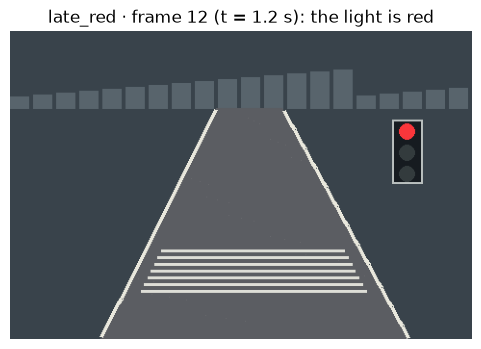

In [4]:
plt.figure(figsize=(6, 4)); plt.imshow(load("late_red", 12).astype(np.uint8)); plt.axis("off")
plt.title("late_red · frame 12 (t = 1.2 s): the light is red"); plt.show()

Baseline (part (b) rule) on that row:

In [5]:
thv1, thv2, thv3 = 0.7, 0.3, 0.5
RANK = {"GO": 0, "SLOW": 1, "STOP": 2}

def baseline_light(v2x_light, red_score):
    if v2x_light == "red":
        return ("STOP", "red signal and red_score high") if red_score > thv1 else ("SLOW", "contradictory evidence between the light signal and the red_score")
    return ("GO", "signal green and red_score low") if red_score < thv2 else ("SLOW", "conflicting evidence between the light signal and the red_score")

def baseline_decide(v2x_light, red_score, person_score):
    d1, r1 = baseline_light(v2x_light, red_score)
    d2 = "STOP" if person_score > thv3 else "GO"   # CHANGED (same as part b): a person means a complete stop
    return max(d1, d2, key=RANK.get), r1

print(f"V2X says {row.v2x_light}, sampled at {row.v2x_sample_time_s} s, now {row.time_s} s -> age {row.age} s; red_score = {row.red_score}")
decision, why = baseline_decide(row.v2x_light, row.red_score, row.person_score)
print(f"baseline decision: {decision} ({why})")

V2X says green, sampled at 0.6 s, now 1.2 s -> age 0.6 s; red_score = 0.911
baseline decision: SLOW (conflicting evidence between the light signal and the red_score)


The message says **green** but is 0.6 s old, and the light is already red (`red_score` 0.911). The baseline only says **SLOW** when the car must **STOP**.

## 2 · Image measurements
- **ROI:** only `img[80:, :]` is used. Rows below are ROI rows (original row − 80).
- **`dark_blue`:** the person's body colour, read at original `(220, 350)` of `person_crossing` frame 11. The light housing is a different dark colour, so an exact match ignores it.
- **`boundary`:** rightmost white pixel per row, from `person_crossing` frame 0 (no person).
- **Lamps:** fixed boxes, red rows 96–112, green rows 140–156 (ROI 16–32 and 60–76), columns 404–420.

In [6]:
# --- region of interest: only the image from row 80 down is used (the sky and buildings above are cut off) ---
ROI_TOP = 80                                               # CHANGED: new
def roi(img):
    return img[ROI_TOP:, :]                                 # CHANGED: new, img[80:, ...]

# --- the person's colour, read from a frame with a person -------------------------
dark_blue = roi(load("person_crossing", 11))[220 - ROI_TOP, 350]   # RGB of the person's body (CHANGED: read from the ROI)
dark_blue_sum = int(dark_blue.sum())                       # the r+g+b value
print("dark_blue =", dark_blue, " r+g+b =", dark_blue_sum)

# --- the right road boundary, read from a frame with no person ---------------------
WHITE_MIN = 200                                            # a pixel is "white" if r, g and b are all >= 200
def white_mask(img):
    return (img >= WHITE_MIN).all(axis=2)

ref_white = white_mask(roi(load("person_crossing", 0)))   # CHANGED: boundary is stored from the ROI
boundary = np.array([np.where(r)[0].max() if r.any() else -1 for r in ref_white])   # rightmost white pixel per row
print("boundary at original rows 200, 223, 300:", boundary[[200 - ROI_TOP, 223 - ROI_TOP, 300 - ROI_TOP]])   # CHANGED: ROI row = original row - 80

# --- the traffic-light lamps (fixed boxes: rows, cols) ----------------------------
RED_LAMP   = (slice(96 - ROI_TOP, 113 - ROI_TOP),  slice(404, 421))     # CHANGED: rows shifted into ROI coordinates
GREEN_LAMP = (slice(140 - ROI_TOP, 157 - ROI_TOP), slice(404, 421))     # CHANGED: rows shifted into ROI coordinates

dark_blue = [24 35 43]  r+g+b = 102
boundary at original rows 200, 223, 300: [341 352 392]


## 3 · The rule
- **Person:** no dark-blue pixel → GO. Leftmost dark-blue pixel at or left of the stored boundary → **STOP** (on the road). Right of it → **SLOW** (outside, might cross).
- **Light:** red lamp lit → STOP, green lit → GO, neither → SLOW (fallback).
- **Final:** the more cautious of the two.

In [7]:
def person_rule(img):
    """Returns (decision, reason, (row, col) of the leftmost dark-blue pixel or None)."""
    ys, xs = np.where((img == dark_blue).all(axis=2))       # all pixels with the person's colour
    if len(ys) == 0:
        return "GO", "no person in the image, nothing to stop for", None
    i = xs.argmin()                                          # leftmost dark-blue pixel
    y, x = int(ys[i]), int(xs[i])
    if x <= boundary[y]:                                     # reached / crossed the right boundary
        return "STOP", "person is on the road and may get hit", (y, x)
    return "SLOW", "PERSON MIGHT CROSS THE ROAD ANYTIME", (y, x)

def light_rule(img):
    """Returns (decision, reason, light) where light is 'red', 'green' or 'unknown'."""
    def lit(box, cond):
        px = img[box]
        return cond(px).sum() > 0.5 * px.shape[0] * px.shape[1]   # more than half of the lamp box is lit
    if lit(RED_LAMP, lambda p: (p[..., 0] > 200) & (p[..., 1] < 90) & (p[..., 2] < 90)):
        return "STOP", "red signal so don't move", "red"
    if lit(GREEN_LAMP, lambda p: (p[..., 1] > 180) & (p[..., 0] < 100) & (p[..., 2] < 140)):
        return "GO", "its obvious, nothing is stopping you", "green"
    return "SLOW", "the light cannot be read from the image", "unknown"

def decide_image(img):
    img = roi(img)                                           # CHANGED: crop first, every calculation below uses the ROI
    pd_, pr, pos = person_rule(img)
    ld, lr, light = light_rule(img)
    return dict(decision=max(pd_, ld, key=RANK.get), person=pd_, light=ld, light_seen=light,
                leftmost_px=pos, reason=f"light: {lr} | person: {pr}")

## 4 · Run on all three episodes

### Decision counts per episode

In [8]:
res = [decide_image(load(r.episode, r.frame)) for r in ev.itertuples()]
out = pd.DataFrame(res)
ev["baseline"] = [baseline_decide(l, rs, ps)[0] for l, rs, ps in zip(ev.v2x_light, ev.red_score, ev.person_score)]
ev["revised"], ev["revised_reason"] = out.decision, out.reason
ev["light_seen"], ev["leftmost_px"] = out.light_seen, out.leftmost_px
ev["boundary_x"] = [boundary[p[0]] if p else None for p in out.leftmost_px]

pd.set_option("display.max_colwidth", None, "display.width", 250)
order = ["GO", "SLOW", "STOP"]
pd.concat({r: ev.groupby("episode")[r].value_counts().unstack(fill_value=0).reindex(columns=order, fill_value=0).rename_axis(columns=None)
           for r in ["baseline", "revised"]}, axis=1).loc[EPISODES]

baseline           revised          
                      GO SLOW STOP      GO SLOW STOP
episode                                             
clear_green           20    1    3      24    0    0
late_red               8    4   12       9    0   15
person_crossing        9    0   15       7    3   14

### Decisions per frame

In [9]:
from IPython.display import display, Markdown

cols = ["time_s", "age", "v2x_light", "light_seen", "leftmost_px", "boundary_x", "baseline", "revised"]
for ep in EPISODES:
    t = ev[ev.episode == ep].set_index("frame")[cols].copy()
    t["leftmost_px"] = t.leftmost_px.map(lambda p: "-" if p is None else p)
    t["boundary_x"] = t.boundary_x.map(lambda x: "-" if pd.isna(x) else int(x))
    t = t.rename(columns={"age": "age_s", "leftmost_px": "person foot (ROI row, col)", "boundary_x": "boundary x"})
    display(Markdown(f"#### {ep}"))
    display(t)

#### clear_green

,time_s,age_s,v2x_light,light_seen,"person foot (ROI row, col)",boundary x,baseline,revised
frame,,,,,,,,
0,0.0,0.0,green,green,-,-,GO,GO
1,0.1,0.0,green,green,-,-,GO,GO
2,0.2,0.0,green,green,-,-,GO,GO
3,0.3,0.0,green,green,-,-,GO,GO
4,0.4,0.0,green,green,-,-,GO,GO
5,0.5,0.5,green,green,-,-,GO,GO
6,0.6,0.6,green,green,-,-,STOP,GO
7,0.7,0.0,green,green,-,-,STOP,GO
8,0.8,0.0,green,green,-,-,GO,GO


#### late_red

,time_s,age_s,v2x_light,light_seen,"person foot (ROI row, col)",boundary x,baseline,revised
frame,,,,,,,,
0,0.0,0.0,green,green,-,-,GO,GO
1,0.1,0.0,green,green,-,-,STOP,GO
2,0.2,0.0,green,green,-,-,GO,GO
3,0.3,0.0,green,green,-,-,GO,GO
4,0.4,0.0,green,green,-,-,GO,GO
5,0.5,0.5,green,green,-,-,GO,GO
6,0.6,0.6,green,green,-,-,GO,GO
7,0.7,0.0,green,green,-,-,GO,GO
8,0.8,0.0,green,green,-,-,GO,GO


#### person_crossing

,time_s,age_s,v2x_light,light_seen,"person foot (ROI row, col)",boundary x,baseline,revised
frame,,,,,,,,
0,0.0,0.0,green,green,-,-,GO,GO
1,0.1,0.0,green,green,-,-,GO,GO
2,0.2,0.0,green,green,-,-,GO,GO
3,0.3,0.0,green,green,-,-,GO,GO
4,0.4,0.0,green,green,-,-,GO,GO
5,0.5,0.5,green,green,-,-,GO,GO
6,0.6,0.6,green,green,-,-,GO,GO
7,0.7,0.0,green,green,"(143, 377)",352,STOP,SLOW
8,0.8,0.0,green,green,"(143, 367)",352,STOP,SLOW


### Frames where the revised rule differs from the baseline

In [10]:
diff = ev[ev.revised != ev.baseline].set_index(["episode", "frame"])[["age", "baseline", "revised", "revised_reason"]]
diff.style.format({"age": "{:.1f}"}).set_properties(subset=["revised_reason"], **{"text-align": "left", "white-space": "normal", "min-width": "430px"})

## 5 · Notes and limits
- **V2X** is never read, so an old message can't mislead. If no lamp is lit the car goes SLOW.
- **Boundary:** the road sways, so the true boundary at the person's row moves between x = 352 and 364; the frame-0 value can be off by ~12 px.
- **Leftmost pixel** is the person's foot (ROI row 143), not the whole body.
- **Exact colour:** another clothing colour would need a tolerance.

## Part (d): is the first STOP timely?
`d_stop = v·τ + v²/(2a)` with `τ = 0.15 s`, `a = 0.8 m/s²`, `v = speed_mps` at the first STOP of each episode.
`d_stop ≤ distance_to_line_m` → can stop comfortably, otherwise can't. No STOP → "no STOP request".

In [11]:
tau = 0.15    # s, total processing + actuation delay
a = 0.8       # m/s^2, comfortable braking magnitude

def stopping_distance(v):
    return v * tau + v**2 / (2 * a)

for rule in ["revised", "baseline"]:
    for ep in EPISODES:
        stops = ev[(ev.episode == ep) & (ev[rule] == "STOP")]
        if stops.empty:
            print(f"[{rule}] {ep}: no STOP request")
            continue
        r = stops.iloc[0]                                   # first STOP request
        d_stop = stopping_distance(r.speed_mps)
        ok = d_stop <= r.distance_to_line_m
        print(f"[{rule}] {ep}: d_stop = {d_stop:.2f} m {'<=' if ok else '>'} distance_to_line = {r.distance_to_line_m} m"
              f" -> {'can' if ok else 'cannot'} comfortably stop")

[revised] clear_green: no STOP request
[revised] late_red: d_stop = 0.52 m <= distance_to_line = 2.03 m -> can comfortably stop
[revised] person_crossing: d_stop = 0.52 m <= distance_to_line = 1.95 m -> can comfortably stop
[baseline] clear_green: d_stop = 0.52 m <= distance_to_line = 2.27 m -> can comfortably stop
[baseline] late_red: d_stop = 0.52 m <= distance_to_line = 2.67 m -> can comfortably stop
[baseline] person_crossing: d_stop = 0.52 m <= distance_to_line = 2.19 m -> can comfortably stop


## Part (e): dropping frames, 20 trials
**Same for baseline and revision:** fixed seed `SEED`; each trial drops `k` frames, `k` random in 1–36, at `k` different CSV lines in 2–73 (image and row both lost).

**Dropped frame:** the car keeps its previous decision of the episode (SLOW if the episode's first frame is dropped). Decisions are per frame, so they are computed once.

**Scoring** (reference file, all 72 frames, held decisions):
- **missed STOP:** required, not STOP. **unnecessary STOP:** not required, STOP.
- **delay:** first required frame → first STOP at or after it, or `none` (only `late_red`, `person_crossing`).

In [12]:
SEED = 42            # stated random seed
N_TRIALS = 20        # at least 20
N_ROWS = len(ev)     # 72 frames = lines 2..73 of the csv
rng = np.random.default_rng(SEED)

ref = pd.read_csv(DATA + "crossing_reference.csv")        # SCORING ONLY, never read by a rule
assert (ref.episode == ev.episode).all() and (ref.frame == ev.frame).all()

full = {"baseline": ev.baseline.to_numpy(), "revised": ev.revised.to_numpy()}   # per-frame decisions, no drops

def held(decisions, dropped_rows):
    """Decisions the car actually holds: on a dropped frame keep the previous decision of the same episode."""
    out, prev = [], None
    for i in range(N_ROWS):
        if ev.frame[i] == 0:
            prev = None                                   # new episode: forget the previous decision
        if i not in dropped_rows:
            prev = decisions[i]
        out.append(prev if prev is not None else "SLOW")  # first frame dropped -> cautious default
    return np.array(out)

def score(dec):
    """missed, unnecessary, and delay (s) from first required frame to first STOP for every episode that requires STOP."""
    need = ref.stop_required.to_numpy() == 1
    missed, unnecessary = int((need & (dec != "STOP")).sum()), int((~need & (dec == "STOP")).sum())
    delay = {}
    for ep in ["late_red", "person_crossing"]:
        m = (ev.episode == ep).to_numpy()
        t_req = ev.time_s[m & need].min()
        stops = ev.time_s[m & (dec == "STOP") & (ev.time_s >= t_req)]   # first STOP at/after the first required frame (an earlier STOP is an unnecessary STOP)
        delay[ep] = round(stops.min() - t_req, 2) if len(stops) else "none"
    return missed, unnecessary, delay

### Results of the 20 trials (rows = trials, `no drop` = nothing dropped)

In [13]:
rows = []
clean = {r: score(full[r]) for r in full}                 # reference row: nothing dropped
for rule, (m, u, d) in clean.items():
    rows.append(dict(trial="no drop", n_dropped=0, rule=rule, missed_STOP=m, unnecessary_STOP=u,
                     delay_late_red=d["late_red"], delay_person_crossing=d["person_crossing"]))

trial_drops = {}
for t in range(1, N_TRIALS + 1):
    k = int(rng.integers(1, 37))                                         # 1..36 frames dropped
    lines = rng.choice(np.arange(2, 74), size=k, replace=False)          # csv lines 2..73, all different
    dropped = set((lines - 2).tolist())                                  # line n -> row index n - 2
    trial_drops[t] = sorted(lines.tolist())
    for rule in full:
        m, u, d = score(held(full[rule], dropped))
        rows.append(dict(trial=t, n_dropped=k, rule=rule, missed_STOP=m, unnecessary_STOP=u,
                         delay_late_red=d["late_red"], delay_person_crossing=d["person_crossing"]))
table = pd.DataFrame(rows)
metrics = {"missed_STOP": "missed STOP", "unnecessary_STOP": "unnecessary STOP",
           "delay_late_red": "delay late_red (s)", "delay_person_crossing": "delay person_crossing (s)"}
wide = pd.concat({rule: table[table.rule == rule].set_index(["trial", "n_dropped"])[list(metrics)].rename(columns=metrics)
                  for rule in ["baseline", "revised"]}, axis=1)
wide

baseline                                                                   revised                                                              
                  missed STOP unnecessary STOP delay late_red (s) delay person_crossing (s) missed STOP unnecessary STOP delay late_red (s) delay person_crossing (s)
trial   n_dropped                                                                                                                                                    
no drop 0                   6                7                0.2                       0.0           0                0                0.0                       0.0
1       4                   6                7                0.2                       0.0           0                0                0.0                       0.0
2       8                   6                5                0.2                       0.0           0                0                0.0                       0.0
3       29                  2                5                0.2                       0.0           2                0                0.1                       0.1
4       6                   6                5                0.2                       0.0           0                0                0.0                       0.0
5       33                  8                7                0.2                       0.0           0                0                0.0                       0.0
6       36                  7                6                0.6                       0.0           3                0                0.3                       0.0
7       1                   6                7                0.2                       0.0           0                0                0.0                       0.0
8       18                  5                8                0.5                       0.0           1                0                0.0                       0.1
9       11                  7                6                0.5                       0.0           0                0                0.0                       0.0
10      35                  5                6                0.2                       0.0           0                0                0.0                       0.0
11      9                   6                7                0.2                       0.0           0                0                0.0                       0.0
12      1                   6                7                0.2                       0.0           0                0                0.0                       0.0
13      35                  8                8                0.6                       0.0           4                0                0.3                       0.1
14      18                  6                7                0.2                       0.0           1                0                0.1                       0.0
15      28                  2                2                0.2                       0.0           0                0                0.0                       0.0
16      30                  7                5                0.2                       0.1           1                0                0.0                       0.1
17      30                  8                5                0.5                       0.0           1                0                0.1                       0.0
18      22                  9                7                0.5                       0.0           1                0                0.1                       0.0
19      18                  7                6                0.2                       0.0           0                0                0.0                       0.0
20      29                  5                5                0.2                       0.0           2                0                0.1                       0.1

### Summary over the 20 trials

In [14]:
# summary over the 20 trials
tt = table[table.trial != "no drop"].copy()
for c in ["delay_late_red", "delay_person_crossing"]:
    tt[c + "_n"] = pd.to_numeric(tt[c], errors="coerce")
summary = tt.groupby("rule").agg(
    missed_total=("missed_STOP", "sum"), missed_mean=("missed_STOP", "mean"),
    unnecessary_total=("unnecessary_STOP", "sum"),
    lr_mean=("delay_late_red_n", "mean"), lr_max=("delay_late_red_n", "max"), lr_none=("delay_late_red", lambda s: (s == "none").sum()),
    pc_mean=("delay_person_crossing_n", "mean"), pc_max=("delay_person_crossing_n", "max"), pc_none=("delay_person_crossing", lambda s: (s == "none").sum()))
summary = summary.T.rename(index={
    "missed_total": "missed STOP frames, total", "missed_mean": "missed STOP frames, mean per trial",
    "unnecessary_total": "unnecessary STOP frames, total",
    "lr_mean": "late_red delay, mean (s)", "lr_max": "late_red delay, max (s)", "lr_none": "late_red: trials with no STOP",
    "pc_mean": "person_crossing delay, mean (s)", "pc_max": "person_crossing delay, max (s)", "pc_none": "person_crossing: trials with no STOP"})
print(f"seed = {SEED}, trials = {N_TRIALS}")
summary[["baseline", "revised"]].style.format("{:g}")

seed = 42, trials = 20


rule,baseline,revised
"missed STOP frames, total",122,16
"missed STOP frames, mean per trial",6.1,0.8
"unnecessary STOP frames, total",121,0
"late_red delay, mean (s)",0.3,0.055
"late_red delay, max (s)",0.6,0.3
late_red: trials with no STOP,0,0
"person_crossing delay, mean (s)",0.005,0.025
"person_crossing delay, max (s)",0.1,0.1
person_crossing: trials with no STOP,0,0


### Reading the table
- **Unnecessary STOPs:** baseline 7 with no drops (121 over 20 trials), revision 0. The baseline STOPs on `person_score` spikes (`clear_green` 6, 7, 9; `late_red` 1) and on a person still outside the road (`person_crossing` 7–9).
- **Missed STOPs:** baseline 6 with no drops (122 total): `late_red` 9, 10, 12, 13 and `person_crossing` 15, 16. Revision 0 (16 total, all from dropped frames).
- **Delay:** `late_red` baseline 0.2 s (up to 0.6 s), revision 0.0 s (up to 0.3 s). `person_crossing` 0.0–0.1 s for both. "none" never occurs.

## One false alarm and one dangerous delay (original frames)

FALSE ALARM · clear_green frame 6: baseline = STOP, revised = GO
  person_score = 0.77 (> thv3 = 0.5), red_score = 0.365 (>= thv2 = 0.3), v2x_light = green, message age = 0.6 s


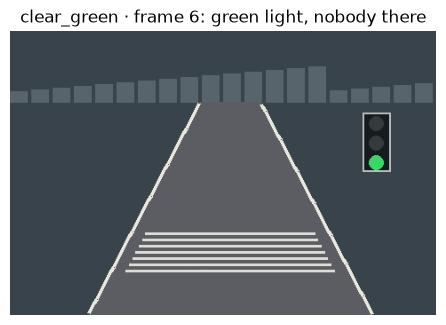

In [15]:
def show(ep, f, title):
    plt.figure(figsize=(5.5, 3.7)); plt.imshow(load(ep, f).astype(np.uint8)); plt.axis("off"); plt.title(title); plt.show()

i = ev[(ev.episode == "clear_green") & (ev.frame == 6)].index[0]
r = ev.loc[i]
print(f"FALSE ALARM · clear_green frame 6: baseline = {r.baseline}, revised = {r.revised}")
print(f"  person_score = {r.person_score} (> thv3 = {thv3}), red_score = {r.red_score} (>= thv2 = {thv2}), v2x_light = {r.v2x_light}, message age = {r.age} s")
show("clear_green", 6, "clear_green · frame 6: green light, nobody there")

DANGEROUS DELAY · late_red frame 9 (first frame where STOP is required): baseline = SLOW, revised = STOP
  red_score = 0.43 (thv1 = 0.7), v2x_light = red, person_score = 0.01; light seen in the image = red
  baseline's first STOP in this episode at/after frame 9: 11


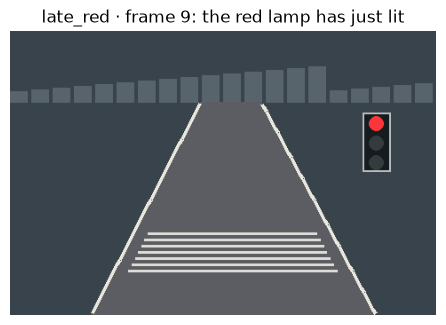

In [16]:
i = ev[(ev.episode == "late_red") & (ev.frame == 9)].index[0]
r = ev.loc[i]
print(f"DANGEROUS DELAY · late_red frame 9 (first frame where STOP is required): baseline = {r.baseline}, revised = {r.revised}")
print(f"  red_score = {r.red_score} (thv1 = {thv1}), v2x_light = {r.v2x_light}, person_score = {r.person_score}; light seen in the image = {r.light_seen}")
print("  baseline's first STOP in this episode at/after frame 9:", int(ev[(ev.episode == 'late_red') & (ev.frame >= 9) & (ev.baseline == 'STOP')].frame.min()))
show("late_red", 9, "late_red · frame 9: the red lamp has just lit")

In [17]:
# worst delay of the revised rule among the 20 trials, and the dropped frames responsible
rv = table[(table.rule == "revised") & (table.trial != "no drop")].copy()
rv["worst"] = rv[["delay_late_red", "delay_person_crossing"]].apply(pd.to_numeric, errors="coerce").max(axis=1)
w = rv.sort_values("worst", ascending=False).iloc[0]
lines = trial_drops[w.trial]
print(f"Worst delay of the revised rule: {w.worst} s in trial {w.trial} ({w.n_dropped} frames dropped)")
print(f"  dropped late_red frames among 9-11: {[l - 2 - 24 for l in lines if 24 + 9 <= l - 2 <= 24 + 11]}")
print(f"  dropped person_crossing frames among 10-11: {[l - 2 - 48 for l in lines if 48 + 10 <= l - 2 <= 48 + 11]}")

Worst delay of the revised rule: 0.3 s in trial 13 (35 frames dropped)
  dropped late_red frames among 9-11: [9, 10, 11]
  dropped person_crossing frames among 10-11: [10]


**False alarm, `clear_green` frame 6 (baseline STOP).** No person and a green light, so GO is right. `person_score` is 0.77 > `thv3` and any such score means STOP; a score is not a calibrated probability. The image rule finds no dark-blue pixel and no red lamp, so it says GO.

**Dangerous delay, `late_red` frame 9 (baseline SLOW).** The red lamp has just lit and V2X says red, but `red_score` is 0.43 < `thv1`, so the baseline only slows. It STOPs at frame 11 (0.2 s late), when `red_score` is 0.99. The image rule sees the lit lamp and STOPs at frame 9. Dropped frames add delay: in trial 13 frames 9–11 are dropped, giving 0.3 s (revision) and 0.6 s (baseline).